<a href="https://colab.research.google.com/github/Jjanz43/MAT-422/blob/main/jjanz1_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:
#Mat 422 1.3

import numpy as np
import matplotlib.pyplot as plt


QR decompoistion factors a matrix A =QR
where Q has orthonormal columns and R is upper triangle matrix.

This decomposition is useful because orthonormal matrices preserve vector lengths and make numeric computation significantly more stable. It also makes the foundation for solving least square oproblems efficiently

In [20]:
I = np.array([
    [1.,2.],
    [3.,4.],
    [5.,6.]
])

Q, R = np.linalg.qr(I)

print("Matrix I")
print(I)

print("\nMatrix Q")
print(Q)

print("\nMatrix R")
print(R)

print("\nQtQ")
print(Q.T @ Q)

print("\nReconstructed I")
print(Q @ R)

print("\nVerification")
print(np.allclose(Q @ R, I))

Matrix I
[[1. 2.]
 [3. 4.]
 [5. 6.]]

Matrix Q
[[-0.16903085  0.89708523]
 [-0.50709255  0.27602622]
 [-0.84515425 -0.34503278]]

Matrix R
[[-5.91607978 -7.43735744]
 [ 0.          0.82807867]]

QtQ
[[1.00000000e+00 6.18439648e-17]
 [6.18439648e-17 1.00000000e+00]]

Reconstructed I
[[1. 2.]
 [3. 4.]
 [5. 6.]]

Verification
True


The QR decomposition successfully factored the matrix into the product


A = QR.


The matrix (Q) has orthonormal columns, which is verified by computing


Q^TQ.


The result is approximately the identity matrix, confirming that each column has unit length and is orthogonal to the others.

Multiplying (Q) and (R) reconstructs the original matrix, demonstrating that no information is lost during the decomposition. QR decomposition is preferred in many numerical algorithms because orthonormal matrices improve computational stability and reduce rounding errors.

Least square probems
Many systems of equations contain more equations than unknowns. Such systems are called overdetermined systems, and they usually do not have an exact solution.

Instead, least squares finds the vector


hat{x}


that minimizes the residual


||b-A\hat{x}||.


This produces the "best fit" solution by making the overall error as small as possible.

In [21]:
A = np.array([
    [1.,1.],
    [1.,2.],
    [1.,3.],
    [1.,4.]
])

c = np.array([6.,5.,7.,10.])

x_hat, residuals, rank, s = np.linalg.lstsq(A,c,rcond=None)

print("Least Squares Solution")
print(x_hat)

residual = c - A @ x_hat

print("\nResidual Vector")
print(residual)

print("\nResidual Norm")
print(np.linalg.norm(residual))

Q,R = np.linalg.qr(A)

x_qr = np.linalg.solve(R, Q.T @ c)

print("\nQR Solution")
print(x_qr)

print("\nSolutions Match")
print(np.allclose(x_hat,x_qr))

print("\nNormal Equation Check")
print(A.T @ residual)

Least Squares Solution
[3.5 1.4]

Residual Vector
[ 1.1 -1.3 -0.7  0.9]

Residual Norm
2.04939015319192

QR Solution
[3.5 1.4]

Solutions Match
True

Normal Equation Check
[-3.55271368e-15 -1.06581410e-14]




Because there are more equations than unknowns, an exact solution generally does not exist.

The least-squares solution minimizes the length of the residual vector


b-A\hat{x}.


The residual norm measures the overall prediction error. A smaller residual norm indicates a better approximation.

The QR decomposition produces the same solution as `np.linalg.lstsq`, confirming that QR decomposition can efficiently solve least-squares problems.

Finally, the product


A^Tr


is approximately zero, which confirms the least-squares optimality condition. This means the residual vector is orthogonal to every column of the matrix (A).



Simple linear regression models the relationship between two variables using the equation


y=\beta_0+\beta_1x.


The coefficients are found by solving a least-squares problem.

The design matrix contains a column of ones for the intercept and a column containing the predictor values.

Intercept = 1.1999999999999975
Slope = 0.942857142857144

Residual Sum of Squares = 1.9428571428571428
RMSE = 0.5690426379538917


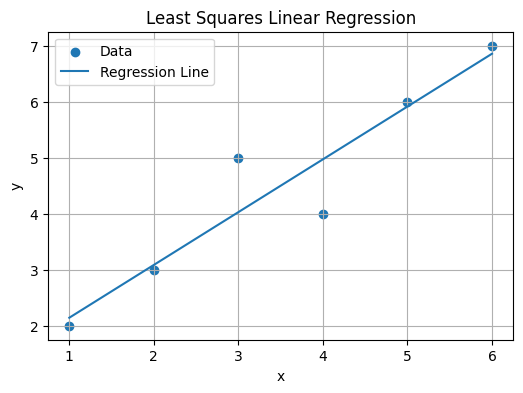

In [23]:
x = np.array([1,2,3,4,5,6])

y = np.array([2,3,5,4,6,7])

X = np.column_stack([np.ones_like(x), x])

beta, residuals, rank, s = np.linalg.lstsq(X,y,rcond=None)

print("Intercept =", beta[0])
print("Slope =", beta[1])

predictions = X @ beta

residual = y - predictions

RSS = np.sum(residual**2)

RMSE = np.sqrt(np.mean(residual**2))

print("\nResidual Sum of Squares =", RSS)
print("RMSE =", RMSE)

plt.figure(figsize=(6,4))


plt.scatter(x,y,label="Data")

plt.plot(x,predictions,label="Regression Line")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Least Squares Linear Regression")

plt.legend()

plt.grid(True)

plt.show()

## Analysis

The least-squares algorithm determined the intercept and slope that best fit the data.

The slope represents the average change in the response variable for each one-unit increase in the predictor variable. The intercept represents the predicted value when the predictor equals zero.

The regression line minimizes the sum of the squared residuals between the observed data points and the predicted values.

The Residual Sum of Squares (RSS) measures the total squared prediction error, while the Root Mean Squared Error (RMSE) measures the average prediction error. Smaller values indicate that the fitted line closely matches the observed data.

The scatter plot and fitted regression line visually demonstrate how least squares finds the line that best represents the data.



This notebook demonstrated the three major concepts from Section 1.3.

- I used QR decomposition to factor a matrix into orthonormal and upper triangular components.
- I verified that (Q^TQ) is approximately the identity matrix and that (QR) reconstructs the original matrix.
- I solved an overdetermined system using least squares and verified the solution using QR decomposition.
- I confirmed the least-squares optimality condition by showing that the residual is orthogonal to the columns of the coefficient matrix.
- I built a simple linear regression model using a design matrix and interpreted the slope, intercept, RSS, and RMSE.



-  All code runs without errors.
-  All required Section 1.3 concepts are demonstrated.
- Numerical verification cells are included.
-  Explanations accompany every section.
-  A graph is included for the regression example.
- ✔I personalized at least one example or explanation.
-  I ran the notebook from top to bottom.
-  I saved the notebook directly from Google Colab to GitHub.
-  The **Open in Colab** badge works correctly from GitHub.